# Phase-Conditioned Inference Guide

This notebook generates a complete respiratory cycle from one preprocessed source CT using a phase-conditioned SynthRCT checkpoint.

1. Generate the ten respiratory states.
2. Save each warped CT, displacement field, and stationary velocity field.
3. Export axial and coronal GIFs.
4. Optionally export a 3D lung GIF with 3D Slicer.


---

## Environment

In [ ]:
from pathlib import Path
import sys

REPO_ROOT = Path.cwd().resolve()
if (REPO_ROOT / "src").exists():
    sys.path.insert(0, str(REPO_ROOT / "src"))

from IPython.display import Image, display

from rctsynth.utils.animation import (
    create_slicer_lung_gif,
    save_volume_gif,
)
from rctsynth.utils.core import model_device
from rctsynth.utils.inference import generate_breathing_cycle
from rctsynth.utils.io import load_nifti_dhw, save_nifti_outputs
from rctsynth.utils.model_loading import load_vae

## Configure paths

The source CT must already have the shape, spacing, orientation, and intensity normalization expected by the checkpoint. The lung mask is only needed for the 3D animation.

In [ ]:
CKPT_PATH = Path("checkpoints/phase_conditioned.ckpt")
SOURCE_NIFTI_PATH = Path("data/demo/preprocessed_ct.nii.gz")
MASK_NIFTI_PATH = Path("data/demo/lung_mask.nii.gz")
OUTPUT_DIR = Path("demo_outputs/phase_cycle")
SLICER_EXECUTABLE = Path("/path/to/Slicer")

DEVICE = "cuda"

PHASE_DIR = OUTPUT_DIR / "phases"
GIF_DIR = OUTPUT_DIR / "gifs"
PHASE_DIR.mkdir(parents=True, exist_ok=True)
GIF_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
source_dhw, nifti_affine = load_nifti_dhw(SOURCE_NIFTI_PATH)
module, model = load_vae(CKPT_PATH, device=DEVICE)

## Generate the breathing cycle

The inference API always generates the ten respiratory states used during training, in cycle order. Each state uses the conditioned prior mean directly and is therefore deterministic.

In [4]:
samples = generate_breathing_cycle(model, source_dhw)

for phase_index, sample in enumerate(samples):
    save_nifti_outputs(
        output_dir=PHASE_DIR,
        affine=nifti_affine,
        warped_dhw=sample.warped_dhw,
        flow_3dhw=sample.flow_3dhw,
        svf_3dhw=sample.svf_3dhw,
        prefix=f"phase_{phase_index:02d}",
    )

print(f"Saved {len(samples)} respiratory states to: {PHASE_DIR}")

Saved 10 respiratory states to: /home/promise/tomasguija/rctsynth/demo_outputs/phase_cycle/phases


## Axial and coronal GIFs

The middle slice is used by default. Pass a `slice_index` to `save_volume_gif` if another anatomical level is preferred.

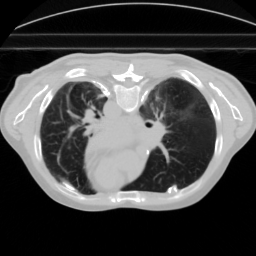

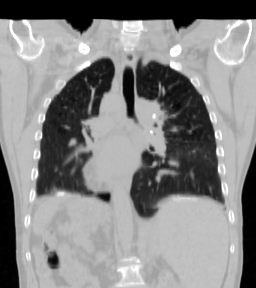

In [5]:
volumes = [sample.warped_dhw for sample in samples]

gif_paths = [
    save_volume_gif(
        volumes,
        GIF_DIR / f"breathing_cycle_{plane}.gif",
        plane=plane,
        fps=4,
        ping_pong=False,
    )
    for plane in ("axial", "coronal")
]

for gif_path in gif_paths:
    display(Image(data=gif_path.read_bytes(), format="gif"))

## Optional 3D lung GIF

This step warps the source lung mask with each predicted deformation and renders the resulting surfaces with 3D Slicer. Set `SLICER_EXECUTABLE` above before running it.

In [ ]:
lung_mask_dhw, _ = load_nifti_dhw(MASK_NIFTI_PATH)

gif_3d_path = create_slicer_lung_gif(
    mask_dhw=lung_mask_dhw,
    samples=samples,
    output_dir=GIF_DIR / "breathing_cycle_lung_3d",
    affine=nifti_affine,
    device=model_device(model),
    slicer_executable=SLICER_EXECUTABLE,
    gif_name="breathing_cycle_lung_3d.gif",
    fps=4,
    ping_pong=False,
)

display(Image(data=gif_3d_path.read_bytes(), format="gif"))